In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pd.set_option("display.max_rows",None)

In [3]:
pd.set_option("display.max_rows",10)

### Dataset Import

In [4]:
data = pd.read_csv('Dataset/gurgaon_properties-outlier removed.csv')
dt = data.copy()

In [5]:
#no. of missing values
num = []
cat = []
for i in dt.columns:
    if dt[i].dtype=='object':
        cat.append(i)
    else:
        num.append(i)

In [6]:
for i in num:
    lenk = dt[dt[i]==0].shape[0]
    if lenk!=0:
        print(i," : ",lenk) 
#all types of area col has missing values rest are just 0 by reason - indicating absence of that facility

Plot area  :  2838
Super Built Up area  :  1577
Built Up area  :  2308
Carpet area  :  1572
Study Room  :  2753
Pooja Room  :  2799
Servant Room  :  2203
Store Room  :  3066
Others  :  2991
Dining Table  :  3226
Curtains  :  2867
Sofa  :  3215
Water Purifier  :  3043
Chimney  :  2332
Geyser  :  2300
Wardrobe  :  2091
Fridge  :  3186
Microwave  :  3147
Stove  :  2951
TV  :  3246
Washing Machine  :  3197
Bed  :  3225
AC  :  2348
Light  :  1665
Fan  :  1932
Exhaust Fan  :  2279
Modular Kitchen  :  2012
furnishing_type  :  2264
luxury score  :  590


In [7]:
for i in cat:
    lenk = dt[dt[i]=='Not Avaliable'].shape[0]
    if lenk!=0:
        print(i," : ",lenk) 

bathroom  :  18
balcony  :  18
floorNum  :  30
facing  :  936


### Built up area

In [8]:
dt[['Built Up area','Super Built Up area']].corr()

,Built Up area,Super Built Up area
Built Up area,1.000000,0.078704
Super Built Up area,0.078704,1.000000


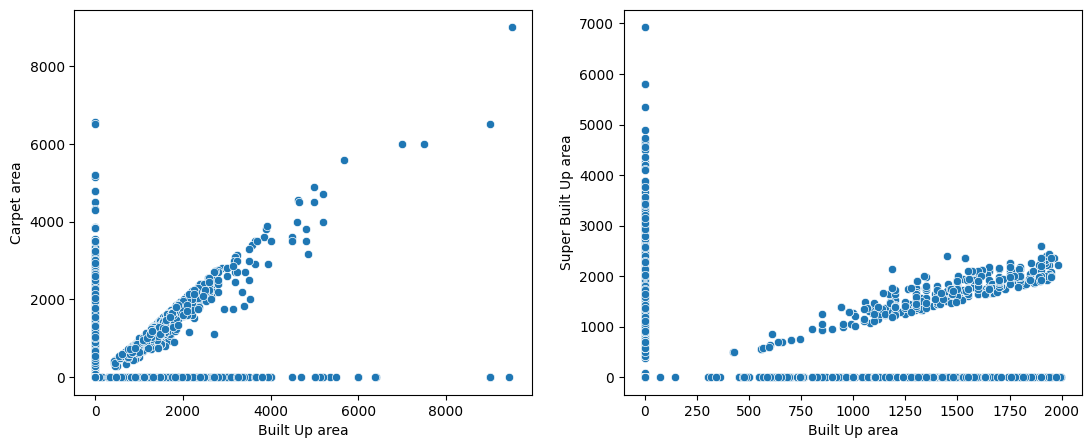

In [9]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.scatterplot(x=dt[dt['Built Up area']<10000]['Built Up area'],y=dt[dt['Carpet area']<10000]['Carpet area'])
plt.subplot(1,2,2)
sns.scatterplot(x=dt[dt['Built Up area']<2000]['Built Up area'],y=dt['Super Built Up area'])

plt.show()

In [10]:
dt[['area','Super Built Up area','Built Up area','Carpet area','Plot area']].corr()

,area,Super Built Up area,Built Up area,Carpet area,Plot area
area,1.000000,-0.018730,-0.010413,0.119467,0.992335
Super Built Up area,-0.018730,1.000000,0.078704,-0.029196,-0.018358
Built Up area,-0.010413,0.078704,1.000000,-0.002294,-0.009755
Carpet area,0.119467,-0.029196,-0.002294,1.000000,-0.001549
Plot area,0.992335,-0.018358,-0.009755,-0.001549,1.000000


In [11]:
dt.shape

(3343, 45)

In [12]:
k = (dt['Built Up area']!=0)
s_to_b = (dt.loc[k,'Super Built Up area']/dt.loc[k,'Built Up area']).median() 
c_to_b = (dt.loc[k,'Carpet area']/dt.loc[k,'Built Up area']).median()

In [13]:
mask = (~(dt['Super Built Up area']==0) & (dt['Built Up area']==0) & ~(dt['Carpet area']==0))
dt[mask].shape

(402, 45)

In [14]:
p = round(
    (
        ( dt.loc[mask]['Super Built Up area']/s_to_b)+(dt.loc[mask]['Carpet area']/c_to_b)
    )/2
    ,3)
dt.loc[mask, 'Built Up area'] = p

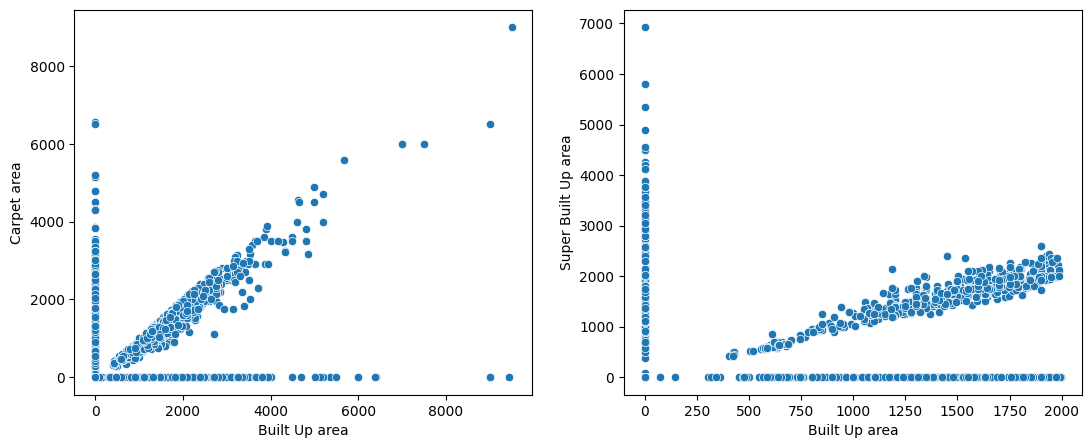

In [15]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.scatterplot(x=dt[dt['Built Up area']<10000]['Built Up area'],y=dt[dt['Carpet area']<10000]['Carpet area'])
plt.subplot(1,2,2)
sns.scatterplot(x=dt[dt['Built Up area']<2000]['Built Up area'],y=dt['Super Built Up area'])
plt.show()

In [16]:
dt[dt['Built Up area']==0].shape

(1906, 45)

In [17]:
mask = (~(dt['Super Built Up area']==0) & (dt['Built Up area']==0) & (dt['Carpet area']==0))
dt[mask].shape

(804, 45)

In [18]:
p = round(
    
        ( dt.loc[mask]['Super Built Up area']/s_to_b)
    
    ,3)
dt.loc[mask, 'Built Up area'] = p

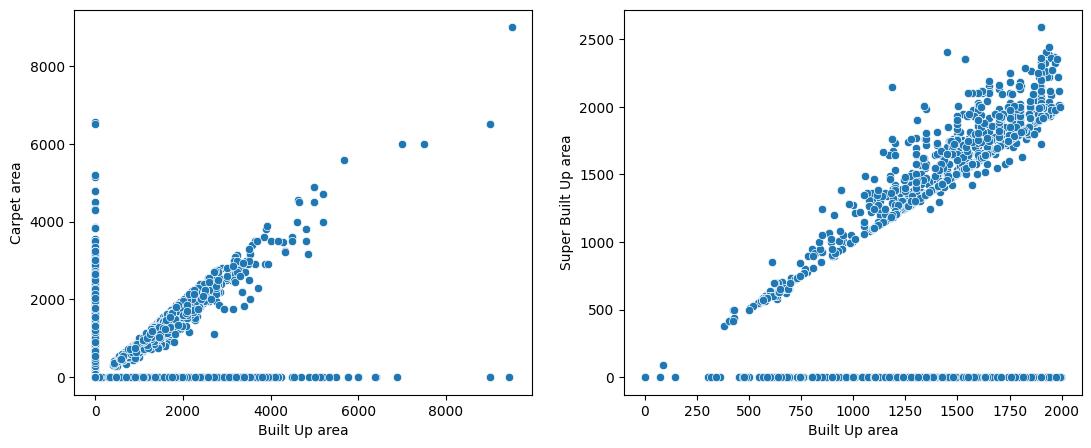

In [19]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.scatterplot(x=dt[dt['Built Up area']<10000]['Built Up area'],y=dt[dt['Carpet area']<10000]['Carpet area'])
plt.subplot(1,2,2)
sns.scatterplot(x=dt[dt['Built Up area']<2000]['Built Up area'],y=dt['Super Built Up area'])
plt.show()

In [20]:
mask = ((dt['Super Built Up area']==0) & (dt['Built Up area']==0) & ~(dt['Carpet area']==0))
dt[mask].shape

(655, 45)

In [21]:
p = round(
    
        ( dt.loc[mask]['Carpet area']/c_to_b)
    
    ,3)
dt.loc[mask, 'Built Up area'] = p

In [22]:
dt[['Super Built Up area','Built Up area','Carpet area']].describe()

,Super Built Up area,Built Up area,Carpet area
count,3343.000000,3343.000000,3343.000000
mean,1018.137894,2325.648036,1382.716611
std,1089.501751,20916.500758,17100.965527
min,0.000000,0.000000,0.000000
25%,0.000000,925.492000,0.000000
50%,950.020000,1567.590000,500.950000
75%,1900.040000,2060.000000,1393.010000
max,6926.030000,744502.869000,607935.380000


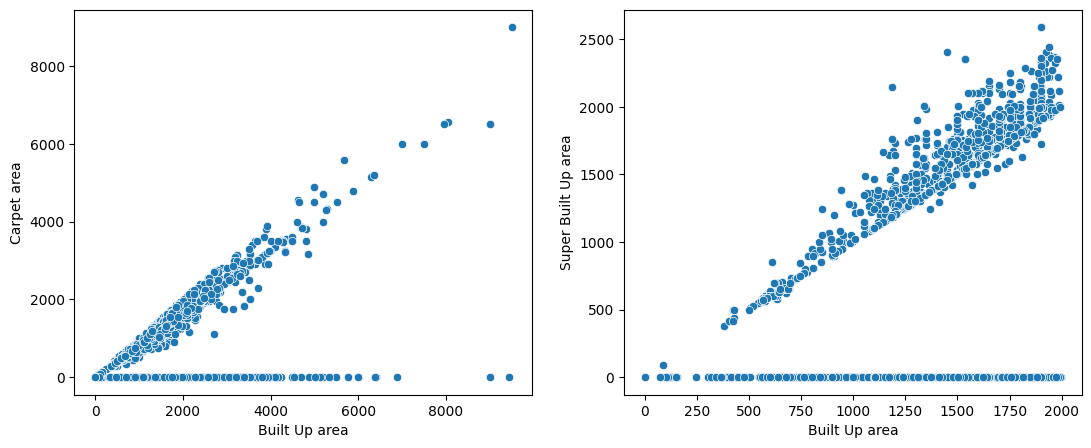

In [23]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.scatterplot(x=dt[dt['Built Up area']<10000]['Built Up area'],y=dt[dt['Carpet area']<10000]['Carpet area'])
plt.subplot(1,2,2)
sns.scatterplot(x=dt[dt['Built Up area']<2000]['Built Up area'],y=dt['Super Built Up area'])
plt.show()

In [24]:
dt = dt[dt['Built Up area']<12000]
mask = ((dt['Super Built Up area']==0) & (dt['Built Up area']==0) & (dt['Carpet area']==0))
print(dt[mask].shape)

dt.loc[((dt['Super Built Up area']==0) & (dt['Built Up area']==0) & (dt['Carpet area']==0)), 'Built Up area'] = dt.loc[((dt['Super Built Up area']==0) & (dt['Built Up area']==0) & (dt['Carpet area']==0)), 'area'].round(2)

print(dt['Built Up area'].value_counts().sort_index())

(447, 45)
Built Up area
75.000         1
88.611         1
93.612         2
94.677         2
94.946         1
              ..
13497.930      1
25994.820      1
82795.920      1
215966.890     1
8711988.510    1
Name: count, Length: 1609, dtype: int64


<Axes: xlabel='Built Up area', ylabel='price'>

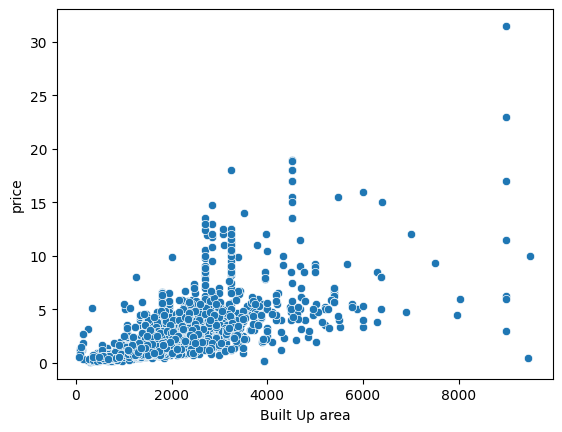

In [25]:
dt = dt[dt['Built Up area']<12000]
sns.scatterplot(dt,x='Built Up area',y='price')

### floorNum

<Axes: ylabel='floorNum'>

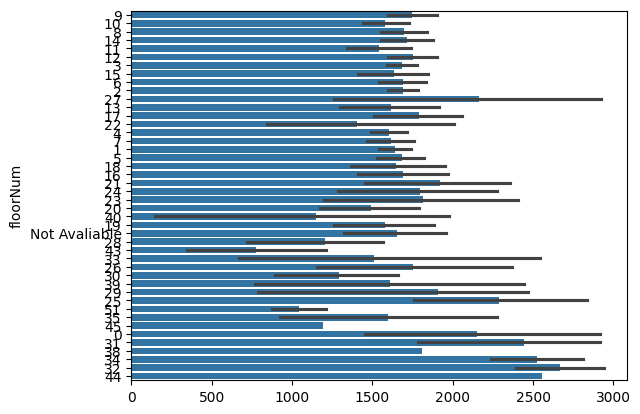

In [26]:
sns.barplot(dt['floorNum'])

In [27]:
dt['floorNum'] = pd.to_numeric(dt['floorNum'], errors='coerce')
dt.groupby('property_type')['floorNum'].agg(['median'])

,median
property_type,
flat,7.0
house,2.0


In [28]:
dt.loc[(dt['property_type']=='house')&(dt['floorNum'].isnull()),'floorNum']=2
dt.loc[(dt['property_type']=='flat')&(dt['floorNum'].isnull()),'floorNum']=7

<Axes: xlabel='floorNum', ylabel='Count'>

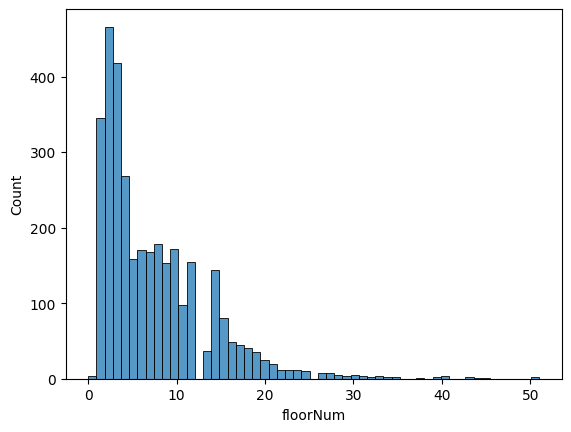

In [29]:
sns.histplot(dt['floorNum'])

### facing

<Axes: ylabel='count'>

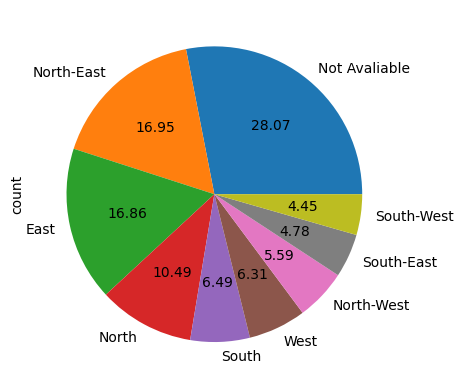

In [30]:
dt['facing'].value_counts().plot(kind='pie',autopct='%0.2f')

In [31]:
 sector_direc = dt.groupby('sector')['facing'].groups

In [32]:
hp= {'South-East':0,'North-West':0, 'South':0, 'South-West':0, 'North-East':0,
       'Not Avaliable':0, 'West':0, 'East':0, 'North':0}
track = pd.DataFrame(columns=['sector','max_direc'])

sector_direc = dt.groupby('sector')['facing'].groups

for x in dt['sector'].unique():
    max_direc = ''
    max_cnt = 0

    for i in sector_direc[x]:
        direc = dt.loc[i, 'facing']

        if direc == 'Not Avaliable':
            continue

        hp[direc] += 1

        if max_direc == '' or max_cnt <= hp[direc]:
            max_direc = direc
            max_cnt = hp[direc]

    
    track.loc[len(track)] = [x, max_direc]
track

,sector,max_direc
0,Sector 81 Gurgaon,East
1,Sector 84 Gurgaon,East
2,Sector 72 Gurgaon,East
3,Sector 69 Gurgaon,North-East
4,Sector 108 Gurgaon,North-East
...,...,...
274,Golf Course Ext Road,
275,"New Colony, Sector 7",East
276,Sector 15 Part 2,North
277,Sector-2 Sohna,North


In [33]:
def transform(row):
    
    if row['facing']=='Not Avaliable':
        sector = row['sector']
        k = track.loc[track['sector']==sector,'max_direc']
        if not k.empty:
            row.loc['facing'] = k.iloc[0]
        else :
            row.loc['facing']=k
    return row;
    

In [34]:
dt = dt[dt['facing']=='Not Avaliable'].apply(transform,axis=1)
dt['facing'].value_counts()

facing
East          488
North-East    317
               82
North          18
West           15
South-East      9
North-West      4
South           1
Name: count, dtype: int64

### agePossession

In [35]:
dt['agePossession'].value_counts()

agePossession
Under Construction    345
Undefined             222
new Property          180
Relatively new        116
old Property           71
Name: count, dtype: int64

In [36]:
def mode_based_imputation1(row):
    if row['agePossession']=='Undefined':
        mode_val = dt[(dt['sector']==row['sector']) & (dt['property_type']==row['property_type'])]['agePossession'].mode()
        if not mode_val.empty:
            return mode_val.iloc[0]
        else:
            return mode_based_imputation2(row)
    else:
        return row['agePossession']

def mode_based_imputation2(row):
    if row['agePossession']=='Undefined':
        mode_val = dt[(dt['sector']==row['sector'])]['agePossession'].mode()
        if not mode_val.empty:
            return mode_val.iloc[0]
        else:
            return mode_based_imputation23(row)
    else:
        return row['agePossession']

def mode_based_imputation3(row):
    if row['agePossession']=='Undefined':
        mode_val = dt[(dt['property_type']==row['property_type'])]['agePossession'].mode()
        if not mode_val.empty:
            return mode_val.iloc[0]
        else:
            return np.nan
    else:
        return row['agePossession']

        

In [37]:
dt['agePossession'] = dt.apply(mode_based_imputation1,axis=1)

### Export File

In [38]:
dt.to_csv('Dataset/gurgaon-properties-missingValue-removed.csv',index=False)
print("successfull")

successfull
